In [1]:
#seeing if we are running on kaggle or not
import os

import numpy as np

iskaggle = os.environ.get("KAGGLE_KERNEL_RUN_TYPE","")

In [2]:
#path in the terminal
!pwd

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course


In [3]:
#path in the notebook
from pathlib import Path
Path.cwd()

PosixPath('/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course')

In [4]:
data_path = Path("../Data/us-patent-phrase-to-phrase-matching")
train_path = data_path / "train.csv"
test_path = data_path / "test.csv"

In [5]:
#lets visualize the Data
import pandas as pd
train_df = pd.read_csv(train_path)
#making the test Data set (but we are going to call it evaluation dataset to avoid confusion)
evaluation_df = pd.read_csv(test_path)
train_df

,id,anchor,target,context,score
0,37d61fd2272659b1,abatement,abatement of pollution,A47,0.50
1,7b9652b17b68b7a4,abatement,act of abating,A47,0.75
2,36d72442aefd8232,abatement,active catalyst,A47,0.25
3,5296b0c19e1ce60e,abatement,eliminating process,A47,0.50
4,54c1e3b9184cb5b6,abatement,forest region,A47,0.00
...,...,...,...,...,...
36468,8e1386cbefd7f245,wood article,wooden article,B44,1.00
36469,42d9e032d1cd3242,wood article,wooden box,B44,0.50
36470,208654ccb9e14fa3,wood article,wooden handle,B44,0.50
36471,756ec035e694722b,wood article,wooden material,B44,0.75


In [6]:
#use the describe
train_df.describe(include="all")

,id,anchor,target,context,score
count,36473,36473,36473,36473,36473.000000
unique,36473,733,29340,106,NaN
top,37d61fd2272659b1,component composite coating,composition,H01,NaN
freq,1,152,24,2186,NaN
mean,NaN,NaN,NaN,NaN,0.362062
std,NaN,NaN,NaN,NaN,0.258335
min,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,0.250000
50%,NaN,NaN,NaN,NaN,0.250000
75%,NaN,NaN,NaN,NaN,0.500000


In [7]:
train_df.describe(include="object")

/tmp/ipykernel_37356/159040709.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train_df.describe(include="object")


,id,anchor,target,context
count,36473,36473,36473,36473
unique,36473,733,29340,106
top,37d61fd2272659b1,component composite coating,composition,H01
freq,1,152,24,2186


In [8]:
#making the thing that is the input that we are going to need for training the (we just leave the other rows for debugging puposes
train_df["input"] = "anchor: " + train_df.anchor + "; target: " + train_df.target + "; context: " + train_df.context

In [9]:
train_df

,id,anchor,target,context,score,input
0,37d61fd2272659b1,abatement,abatement of pollution,A47,0.50,anchor: abatement; target: abatement of pollut...
1,7b9652b17b68b7a4,abatement,act of abating,A47,0.75,anchor: abatement; target: act of abating; con...
2,36d72442aefd8232,abatement,active catalyst,A47,0.25,anchor: abatement; target: active catalyst; co...
3,5296b0c19e1ce60e,abatement,eliminating process,A47,0.50,anchor: abatement; target: eliminating process...
4,54c1e3b9184cb5b6,abatement,forest region,A47,0.00,anchor: abatement; target: forest region; cont...
...,...,...,...,...,...,...
36468,8e1386cbefd7f245,wood article,wooden article,B44,1.00,anchor: wood article; target: wooden article; ...
36469,42d9e032d1cd3242,wood article,wooden box,B44,0.50,anchor: wood article; target: wooden box; cont...
36470,208654ccb9e14fa3,wood article,wooden handle,B44,0.50,anchor: wood article; target: wooden handle; c...
36471,756ec035e694722b,wood article,wooden material,B44,0.75,anchor: wood article; target: wooden material;...


In [10]:
#make the training dataset and getting not making the tokenization and the Numericalization using the hugging face and also get the model
from datasets import Dataset, DatasetDict
#make the dataset from pd
dataset = Dataset.from_pandas(train_df)
#get the model name The format 'organization/modelname' is how HuggingFace identifies models
model = "bert-base-uncased"
#AutoTokenizer — downloads the tokenizer for your chosen model.
#AutoModelForSequenceClassification — downloads the actual model (you'll use this later for training).
from transformers import AutoModelForSequenceClassification, AutoTokenizer
#get tokens
tokens = AutoTokenizer.from_pretrained(model)

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [11]:
#see what the tokenization does(for visual)
tokens.tokenize("i eat potato, brother")

['i', 'eat', 'potato', ',', 'brother']

In [12]:
#see what the tokenization does(what the model really sees)
tokens("i eat potato, brother")

{'input_ids': [101, 1045, 4521, 14557, 1010, 2567, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1]}

In [13]:
#make a funciton that tokenizes what is give (input row)
def tokenizer (x,tokens=tokens):
    return tokens(x["input"])

In [14]:
#make the tokenized dataset
tokenized_dataset = dataset.map(tokenizer, batched=True)
#make the name of the row (scores --> labels), so that the model can read it
tokenized_dataset = tokenized_dataset.rename_columns({"score":"labels"})

Map: 100%|██████████| 36473/36473 [00:00<00:00, 40556.31 examples/s]


In [15]:
#here you can see the input became tokenized
tokenized_dataset

Dataset({
    features: ['id', 'anchor', 'target', 'context', 'labels', 'input', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 36473
})

In [16]:
#making the splits of train and validation
dictionary_dataset_split = tokenized_dataset.train_test_split(test_size=0.2)
dictionary_dataset_split

DatasetDict({
    train: Dataset({
        features: ['id', 'anchor', 'target', 'context', 'labels', 'input', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 29178
    })
    test: Dataset({
        features: ['id', 'anchor', 'target', 'context', 'labels', 'input', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7295
    })
})

In [17]:
#see an example
dictionary_dataset_split["train"][0]

{'id': '64e20563e40a023c',
 'anchor': 'melt coating',
 'target': 'melt wax coating',
 'context': 'B41',
 'labels': 0.5,
 'input': 'anchor: melt coating; target: melt wax coating; context: B41',
 'input_ids': [101,
  8133,
  1024,
  14899,
  18898,
  1025,
  4539,
  1024,
  14899,
  13844,
  18898,
  1025,
  6123,
  1024,
  1038,
  23632,
  102],
 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [18]:
#this is our evaluation (test) Data
evaluation_df

,id,anchor,target,context
0,4112d61851461f60,opc drum,inorganic photoconductor drum,G02
1,09e418c93a776564,adjust gas flow,altering gas flow,F23
2,36baf228038e314b,lower trunnion,lower locating,B60
3,1f37ead645e7f0c8,cap component,upper portion,D06
4,71a5b6ad068d531f,neural stimulation,artificial neural network,H04
5,474c874d0c07bd21,dry corn,dry corn starch,C12
6,442c114ed5c4e3c9,tunneling capacitor,capacitor housing,G11
7,b8ae62ea5e1d8bdb,angular contact bearing,contact therapy radiation,B23
8,faaddaf8fcba8a3f,produce liquid hydrocarbons,produce a treated stream,C10
9,ae0262c02566d2ce,diesel fuel tank,diesel fuel tanks,F02


In [19]:
#make the input
evaluation_df["input"]="anchor: " + evaluation_df.anchor + "; target: " + evaluation_df.target + "; context: " + evaluation_df.context
evaluation_df

,id,anchor,target,context,input
0,4112d61851461f60,opc drum,inorganic photoconductor drum,G02,anchor: opc drum; target: inorganic photocondu...
1,09e418c93a776564,adjust gas flow,altering gas flow,F23,anchor: adjust gas flow; target: altering gas ...
2,36baf228038e314b,lower trunnion,lower locating,B60,anchor: lower trunnion; target: lower locating...
3,1f37ead645e7f0c8,cap component,upper portion,D06,anchor: cap component; target: upper portion; ...
4,71a5b6ad068d531f,neural stimulation,artificial neural network,H04,anchor: neural stimulation; target: artificial...
5,474c874d0c07bd21,dry corn,dry corn starch,C12,anchor: dry corn; target: dry corn starch; con...
6,442c114ed5c4e3c9,tunneling capacitor,capacitor housing,G11,anchor: tunneling capacitor; target: capacitor...
7,b8ae62ea5e1d8bdb,angular contact bearing,contact therapy radiation,B23,anchor: angular contact bearing; target: conta...
8,faaddaf8fcba8a3f,produce liquid hydrocarbons,produce a treated stream,C10,anchor: produce liquid hydrocarbons; target: p...
9,ae0262c02566d2ce,diesel fuel tank,diesel fuel tanks,F02,anchor: diesel fuel tank; target: diesel fuel ...


In [20]:
#making it to df and making tokeniziation for it
eval_tokenized_dataset = Dataset.from_pandas(evaluation_df).map(tokenizer, batched=True)
eval_tokenized_dataset

Map: 100%|██████████| 36/36 [00:00<00:00, 7856.55 examples/s]


Dataset({
    features: ['id', 'anchor', 'target', 'context', 'input', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 36
})

# making the metrix that we are going to use


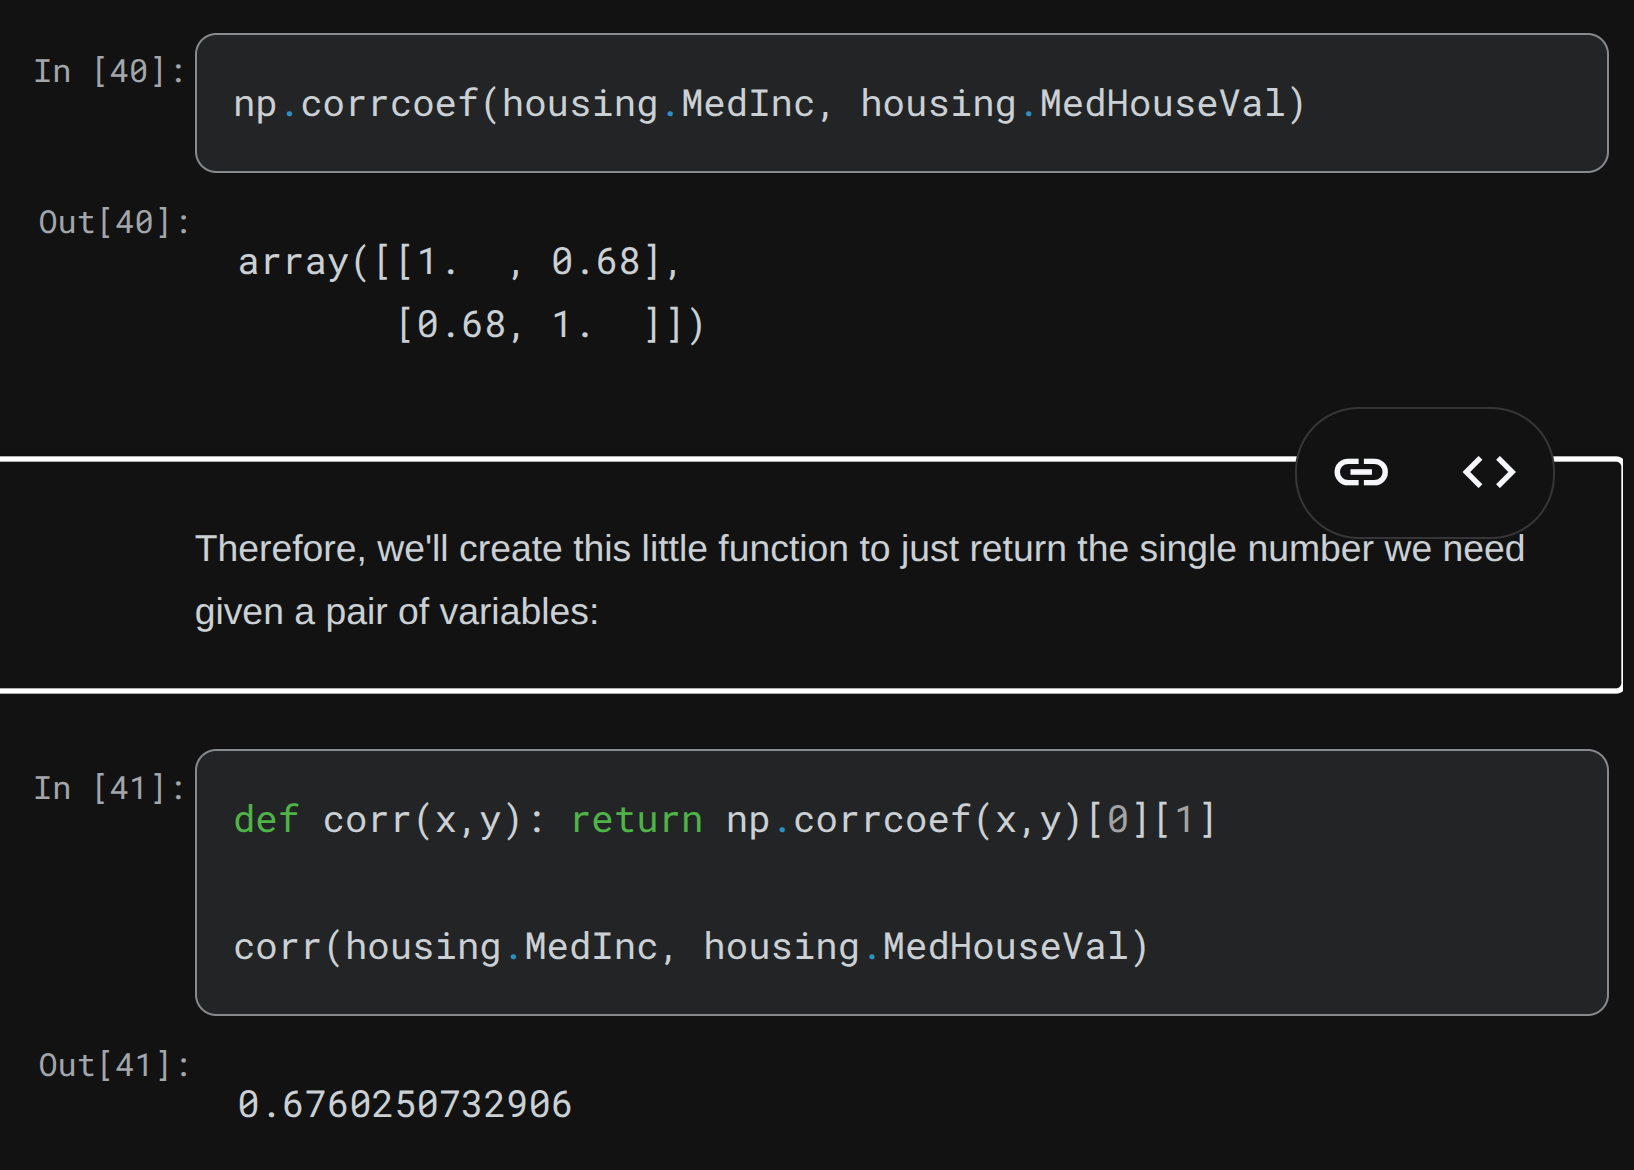"
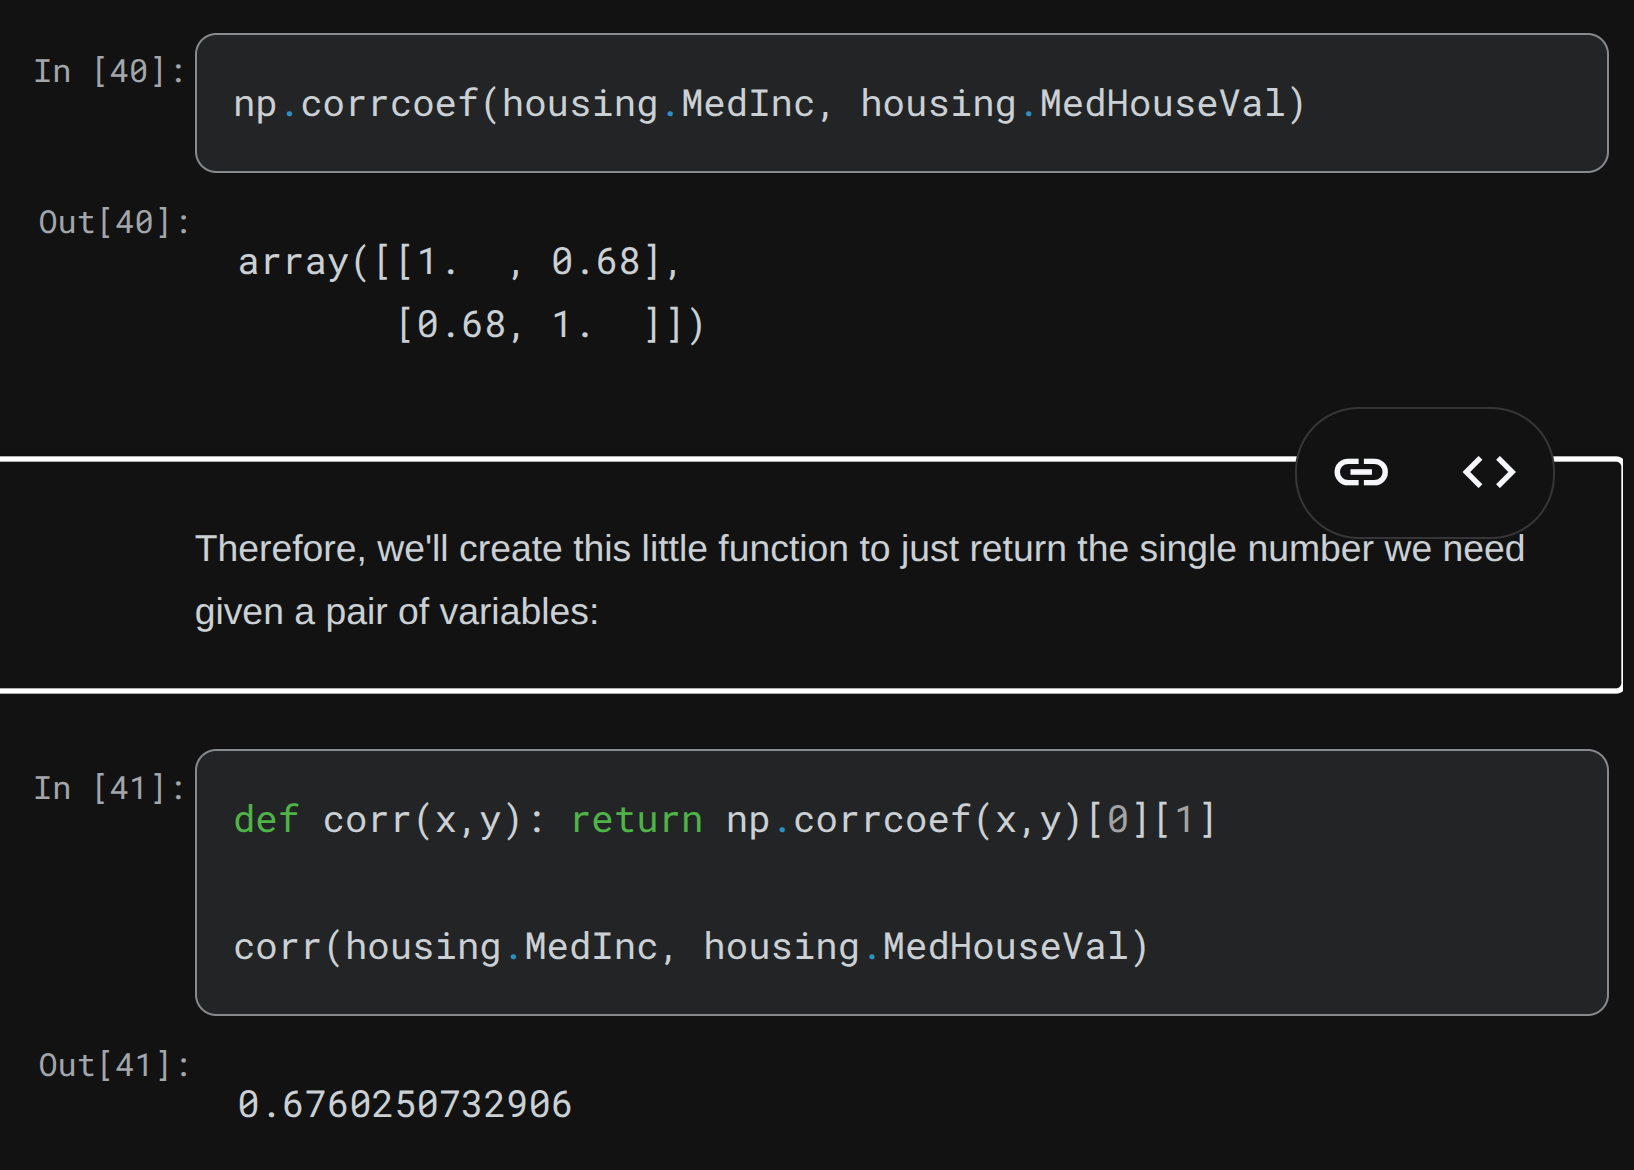

In [21]:
#only works for numeric
import matplotlib.pyplot as plt
def corr (x,y):
    return np.corrcoef(x,y)[0][1]
def corr_plotter (df,a,b):
    x,y = df[a],df[b]
    plt.scatter(x,y,alpha=0.4,s=4,color="red")
    plt.title(f"Correlation between {a} and {b} is {corr(x,y):.2f}")

In [22]:
train_df

,id,anchor,target,context,score,input
0,37d61fd2272659b1,abatement,abatement of pollution,A47,0.50,anchor: abatement; target: abatement of pollut...
1,7b9652b17b68b7a4,abatement,act of abating,A47,0.75,anchor: abatement; target: act of abating; con...
2,36d72442aefd8232,abatement,active catalyst,A47,0.25,anchor: abatement; target: active catalyst; co...
3,5296b0c19e1ce60e,abatement,eliminating process,A47,0.50,anchor: abatement; target: eliminating process...
4,54c1e3b9184cb5b6,abatement,forest region,A47,0.00,anchor: abatement; target: forest region; cont...
...,...,...,...,...,...,...
36468,8e1386cbefd7f245,wood article,wooden article,B44,1.00,anchor: wood article; target: wooden article; ...
36469,42d9e032d1cd3242,wood article,wooden box,B44,0.50,anchor: wood article; target: wooden box; cont...
36470,208654ccb9e14fa3,wood article,wooden handle,B44,0.50,anchor: wood article; target: wooden handle; c...
36471,756ec035e694722b,wood article,wooden material,B44,0.75,anchor: wood article; target: wooden material;...


In [23]:
#see what is numeric in the Data
train_df.select_dtypes(include='number').columns


Index(['score'], dtype='str')

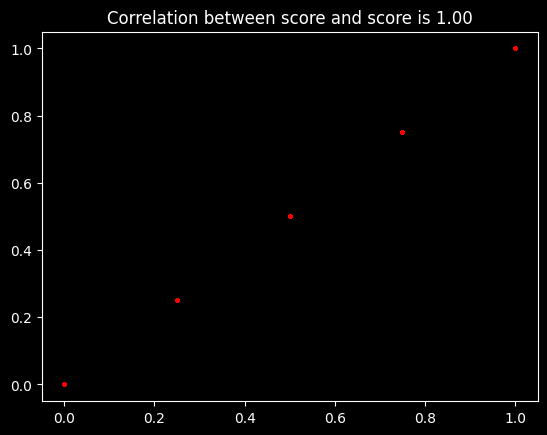

In [24]:
corr_plotter(train_df,"score","score")

In [25]:
#making a function that helps us in tracking when we make the trainer that is in the hugging face ,
# eval_pred — the Trainer automatically passes this in. It's a tuple of (predictions, labels) so we make the (*)
def correlation_dictionary(eval_pred):
    preds = eval_pred.predictions.squeeze()
    labels = eval_pred.label_ids
    return {"pearson": corr(preds, labels)}

In [26]:
# to train the model
import torch
from transformers import TrainingArguments,Trainer
BATCH_SIZE = 32
EPOCHES = 5
LR = 8e-5
#make the args of the training
args = TrainingArguments(
    '../../../finished_stuff/outputs',                           # folder where checkpoints get saved
    learning_rate=LR,
    warmup_ratio=0.1,                    # spend first 10% of training slowly ramping up the lr
                                         # helps stabilise early training with transformers
    lr_scheduler_type='cosine',          # gradually reduce lr over training in a smooth curve
    fp16=torch.cuda.is_available(),      # use 16-bit precision on your RTX 4060 — roughly 2x faster
    eval_strategy="epoch",               # run validation after every epoch so you can watch progress
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,   # validation uses 2x batch size since we don't store gradients
    num_train_epochs=EPOCHES,
    weight_decay=0.01,                   # small penalty on large weights — reduces overfitting
    report_to='none'                     # disables automatic logging to Weights & Biases
)

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [27]:
from transformers import DataCollatorWithPadding

#make the model
loaded_model =AutoModelForSequenceClassification.from_pretrained(model, num_labels=1)
#make the padding that is now needed in the new hugging face to have more control:

# "anchor: fuel; target: gas"→ 8 tokens
# "anchor: combustion engine; target: internal combustion automobile" → 15 tokens

# [584, 1672, 261, 0, 0, 0, 0]   ← padded
# [584, 1672, 891, 234, 567, 891, 234]  ← full length

data_collator = DataCollatorWithPadding(tokenizer=tokens)

#use the huggingface training loop
trainer = Trainer(
    model=loaded_model,
    args=args,
    train_dataset=dictionary_dataset_split['train'],
    eval_dataset=dictionary_dataset_split['test'],
    data_collator=data_collator,         # modern replacement for tokenizer= argument
    compute_metrics=correlation_dictionary
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 5763.79it/s]
BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider tr

In [28]:
#train the model
trainer.train()

Epoch,Training Loss,Validation Loss,Pearson
1,0.063915,0.031415,0.734928
2,0.027194,0.025493,0.791242
3,0.015386,0.024903,0.808037
4,0.009531,0.022599,0.819156
5,0.006716,0.022972,0.819110


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.16it/s]


TrainOutput(global_step=4560, training_loss=0.022142009169124722, metrics={'train_runtime': 426.2088, 'train_samples_per_second': 342.297, 'train_steps_per_second': 10.699, 'total_flos': 1813172447021088.0, 'train_loss': 0.022142009169124722, 'epoch': 5.0})

In [29]:
#making the model predicitons that are needed for the kaggle competiotion
preds = trainer.predict(eval_tokenized_dataset).predictions.astype(float)
preds

array([[ 5.18554688e-01],
       [ 5.35644531e-01],
       [ 2.34497070e-01],
       [ 2.20336914e-01],
       [-2.95066833e-03],
       [ 5.03906250e-01],
       [ 5.00976562e-01],
       [-6.48880005e-03],
       [ 2.34497070e-01],
       [ 1.02050781e+00],
       [ 2.76367188e-01],
       [ 2.57812500e-01],
       [ 7.84179688e-01],
       [ 9.07226562e-01],
       [ 7.49511719e-01],
       [ 3.28857422e-01],
       [ 2.81982422e-01],
       [-8.70513916e-03],
       [ 4.91943359e-01],
       [ 4.82910156e-01],
       [ 4.21875000e-01],
       [ 1.96655273e-01],
       [ 2.80029297e-01],
       [ 2.43041992e-01],
       [ 5.47363281e-01],
       [-5.83267212e-03],
       [ 1.28841400e-03],
       [ 9.17816162e-03],
       [ 8.07285309e-04],
       [ 7.37792969e-01],
       [ 2.19879150e-02],
       [ 2.79808044e-03],
       [ 6.80175781e-01],
       [ 6.04980469e-01],
       [ 3.01269531e-01],
       [ 2.58789062e-01]])

In [30]:
#making a relu to remove x>1 or x<0
preds = np.clip(preds,0,1)
preds

array([[5.18554688e-01],
       [5.35644531e-01],
       [2.34497070e-01],
       [2.20336914e-01],
       [0.00000000e+00],
       [5.03906250e-01],
       [5.00976562e-01],
       [0.00000000e+00],
       [2.34497070e-01],
       [1.00000000e+00],
       [2.76367188e-01],
       [2.57812500e-01],
       [7.84179688e-01],
       [9.07226562e-01],
       [7.49511719e-01],
       [3.28857422e-01],
       [2.81982422e-01],
       [0.00000000e+00],
       [4.91943359e-01],
       [4.82910156e-01],
       [4.21875000e-01],
       [1.96655273e-01],
       [2.80029297e-01],
       [2.43041992e-01],
       [5.47363281e-01],
       [0.00000000e+00],
       [1.28841400e-03],
       [9.17816162e-03],
       [8.07285309e-04],
       [7.37792969e-01],
       [2.19879150e-02],
       [2.79808044e-03],
       [6.80175781e-01],
       [6.04980469e-01],
       [3.01269531e-01],
       [2.58789062e-01]])

In [33]:
#making a submission file
submission = Dataset.from_dict({
    'id' : eval_tokenized_dataset['id'],
    'score' : preds.flatten() # to remove the brackets that are in the output eg--> make it 0.43 not [0.43]
})
submission

Dataset({
    features: ['id', 'score'],
    num_rows: 36
})

In [34]:
#save to csv
submission.to_csv('submission.csv', index=False)

Creating CSV from Arrow format: 100%|██████████| 1/1 [00:00<00:00, 517.24ba/s]


1106